Identify bias in the model predictions by implementing fairness metrics such as disparate impact and equalized odds without using prebuilt fairness libraries, manually computing bias scores across demographic groups.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()
X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight="balanced", random_state=42
    )
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Model trained successfully.")

Model trained successfully.


In [2]:
print("Available columns:", df.columns.tolist())

Available columns: ['patient_id', 'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'chol_percentile', 'thalach_percentile', 'risk_factor', 'risk_category']


In [ ]:
group_column = "sex"

if group_column not in df.columns:
    raise ValueError(
        f"'{group_column}' is not in the dataset. "
        "Choose an existing demographic column."
    )

group_data = df.loc[X_test.index, [group_column]].copy()
group_data["Actual"] = y_test
group_data["Predicted"] = predictions

print(group_data[group_column].value_counts())

sex
Male      10
Female     6
Name: count, dtype: int64


In [4]:
def calculate_group_metrics(data):
    actual = data["Actual"].to_numpy()
    pred = data["Predicted"].to_numpy()

    tp = np.sum((actual == 1) & (pred == 1))
    fp = np.sum((actual == 0) & (pred == 1))
    tn = np.sum((actual == 0) & (pred == 0))
    fn = np.sum((actual == 1) & (pred == 0))

    return {
        "Samples": len(data),
        "Positive Prediction Rate": np.mean(pred == 1),
        "TPR": tp / (tp + fn) if tp + fn else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan
    }


group_results = {}

for group in group_data[group_column].dropna().unique():
    subset = group_data[group_data[group_column] == group]
    group_results[group] = calculate_group_metrics(subset)

fairness_df = pd.DataFrame(group_results).T
print(fairness_df.round(4))

        Samples  Positive Prediction Rate   TPR  FPR
Female      6.0                    0.6667  1.00  0.0
Male       10.0                    0.8000  0.75  1.0


In [5]:
rates = fairness_df["Positive Prediction Rate"].dropna()

if len(rates) >= 2:
    reference_group = rates.idxmax()
    reference_rate = rates.max()

    fairness_df["Disparate Impact Ratio"] = (
        fairness_df["Positive Prediction Rate"] / reference_rate
        if reference_rate > 0 else np.nan
    )

    print("Reference group:", reference_group)
    print("Disparate impact ratios:")
    print(fairness_df["Disparate Impact Ratio"].round(4))
else:
    print("At least two demographic groups are required.")

tpr_values = fairness_df["TPR"].dropna()
fpr_values = fairness_df["FPR"].dropna()

tpr_difference = (
    tpr_values.max() - tpr_values.min()
    if len(tpr_values) >= 2 else np.nan
)

fpr_difference = (
    fpr_values.max() - fpr_values.min()
    if len(fpr_values) >= 2 else np.nan
)

print("Equalized odds TPR difference:", tpr_difference)
print("Equalized odds FPR difference:", fpr_difference)

Reference group: Male
Disparate impact ratios:
Female    0.8333
Male      1.0000
Name: Disparate Impact Ratio, dtype: float64
Equalized odds TPR difference: 0.25
Equalized odds FPR difference: 1.0


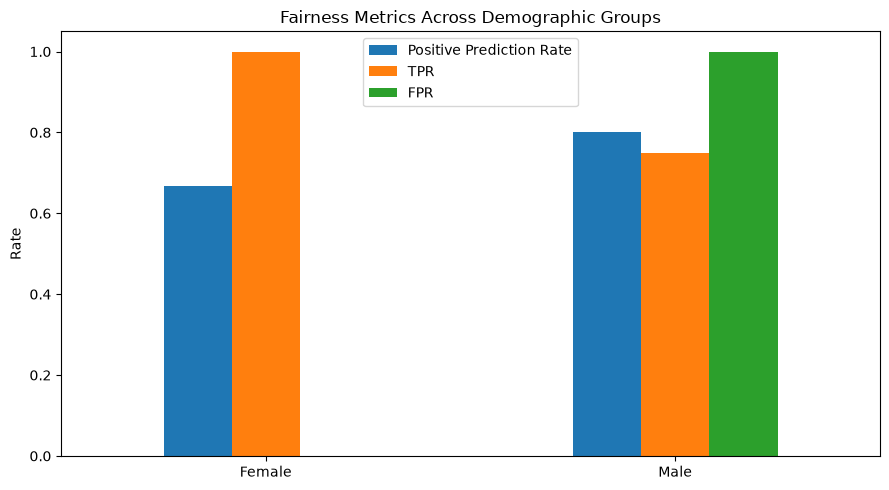

In [6]:
fairness_df[
    ["Positive Prediction Rate", "TPR", "FPR"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Fairness Metrics Across Demographic Groups")
plt.ylabel("Rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()